In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.linear_model as lm
import sklearn.pipeline as pipe
import sklearn.preprocessing as pp
import sklearn.model_selection as ms
import sklearn.ensemble as rf
import sklearn.tree as tree
import numpy as np

In [2]:
df = pd.read_csv("data/heartdisease/data_cleaned_up.csv")
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
0,28,1,2,130,132,0,2,185,0,0.0,0
1,29,1,2,120,243,0,0,160,0,0.0,0
2,30,0,1,170,237,0,1,170,0,0.0,0
3,31,0,2,100,219,0,1,150,0,0.0,0
4,32,0,2,105,198,0,0,165,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...
255,52,1,4,160,331,0,0,94,1,2.5,1
256,54,0,3,130,294,0,1,100,1,0.0,1
257,56,1,4,155,342,1,0,150,1,3.0,1
258,58,0,2,180,393,0,0,110,1,1.0,1


In [3]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,num
count,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000,260.000000
mean,47.792308,0.734615,3.003846,132.688462,248.903846,0.073077,0.226923,139.176923,0.315385,0.608846,0.376923
std,7.849153,0.442389,0.972590,17.726555,65.781861,0.260765,0.471634,23.789932,0.465565,0.932075,0.485550
min,28.000000,0.000000,1.000000,92.000000,85.000000,0.000000,0.000000,82.000000,0.000000,0.000000,0.000000
25%,42.000000,0.000000,2.000000,120.000000,207.750000,0.000000,0.000000,122.000000,0.000000,0.000000,0.000000
50%,49.000000,1.000000,3.000000,130.000000,242.500000,0.000000,0.000000,140.000000,0.000000,0.000000,0.000000
75%,54.000000,1.000000,4.000000,140.000000,280.000000,0.000000,0.000000,155.000000,1.000000,1.000000,1.000000
max,65.000000,1.000000,4.000000,200.000000,603.000000,1.000000,2.000000,190.000000,1.000000,5.000000,1.000000


(array([ 5., 15., 27., 21., 36., 48., 34., 49., 19.,  6.]),
 array([28. , 31.7, 35.4, 39.1, 42.8, 46.5, 50.2, 53.9, 57.6, 61.3, 65. ]),
 <BarContainer object of 10 artists>)

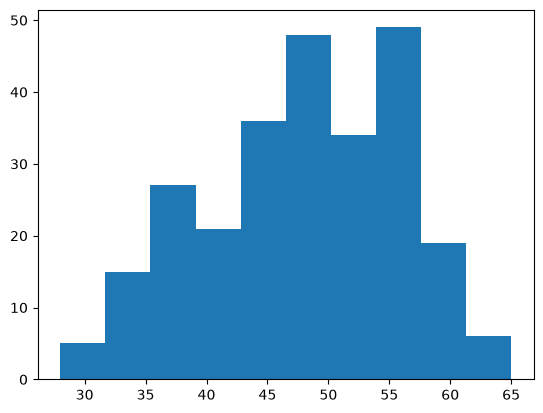

In [4]:
plt.hist(df["age"], bins=10)

In [5]:
y = df["num"]
x = df.drop(["num"], axis=1)
x.shape

(260, 10)

In [6]:
xtrain, xtest, ytrain, ytest = ms.train_test_split(x, y, train_size=0.8, test_size=0.2)

In [7]:
scaler = pp.RobustScaler()
scaler.fit(xtrain)
xtrain = scaler.transform(xtrain)
xtest = scaler.transform(xtest)
xtest[:10]

array([[ 0.07692308,  0.        ,  0.5       , -0.1       , -0.45864662,
         0.        ,  0.        , -1.3968254 ,  1.        ,  0.        ],
       [ 0.76923077,  0.        ,  0.        ,  0.5       , -0.95488722,
         0.        ,  0.        ,  0.63492063,  0.        ,  0.        ],
       [-0.15384615,  0.        ,  0.5       , -1.        , -0.06766917,
         0.        ,  1.        ,  0.        ,  1.        ,  1.        ],
       [ 0.30769231,  0.        , -0.5       ,  1.5       , -0.69924812,
         0.        ,  0.        ,  0.79365079,  0.        ,  0.        ],
       [ 0.46153846,  0.        , -1.        , -0.5       , -1.07518797,
         0.        ,  0.        , -0.0952381 ,  0.        ,  2.        ],
       [ 0.84615385,  0.        , -0.5       ,  0.5       ,  0.66917293,
         0.        ,  0.        ,  0.31746032,  0.        ,  0.        ],
       [ 0.07692308,  0.        ,  0.5       ,  0.        , -0.54887218,
         0.        ,  0.        ,  0.95238095

In [8]:
model = rf.RandomForestClassifier()

In [9]:
model.fit(xtrain, ytrain)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [10]:
model.score(xtest, ytest)

0.7692307692307693

In [13]:
tree.export_graphviz(model.estimators_[0], out_file="data/heartdisease/tree.dot", feature_names=x.columns, class_names=["0","1"])

In [14]:
model.feature_importances_

array([0.08327703, 0.02938266, 0.15295589, 0.09013814, 0.13565153,
       0.0091386 , 0.02026947, 0.12141008, 0.128684  , 0.2290926 ])

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'age'),
  Text(1, 0, 'sex'),
  Text(2, 0, 'cp'),
  Text(3, 0, 'trestbps'),
  Text(4, 0, 'chol'),
  Text(5, 0, 'fbs'),
  Text(6, 0, 'restecg'),
  Text(7, 0, 'thalach'),
  Text(8, 0, 'exang'),
  Text(9, 0, 'oldpeak')])

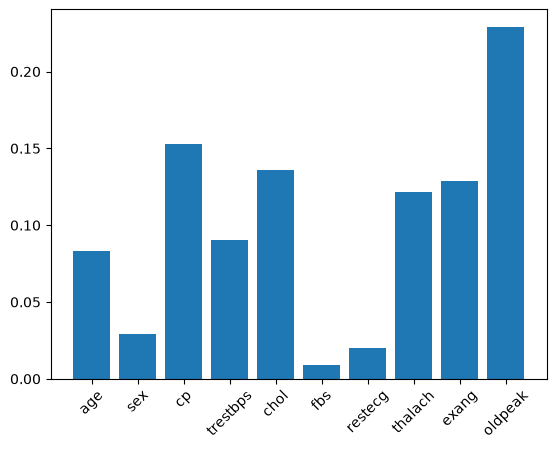

In [17]:
plt.bar(x.columns, model.feature_importances_)
plt.xticks(rotation=45)